# Project

### Group L : Taïs Thomas, Marouchka Heck, Marie-Caroline Bilocq

### Question 1
Compute the density ($g.cm^{-3}$), accessible surface area - ASA ($A^2$), accessible probe-occupiable volume - POAV ($A^3$) and porosity of the different structures by running pore analysis.

We first characterize the pore properties of the five MOF structures: Mg-MOF-74, NOTT-300, UTSA-20, UTSA-80 and ZIF-8.
For each structure, we compute the density, accessible surface area (ASA), accessible probe-occupiable volume (POAV), and porosity using Zeo++.
A probe radius of 1.525 Å is used.

| Structure | Density ($g.cm^{-3}$) | ASA ($A^2$) | POAV ($A^3$) | Porosity |
|---|---:|---:|---:|---:|
| Mg-MOF-74 | 0.886275 | 222.828 | 837.198 | 0.61368 |
| NOTT-300 | 1.03926 | 453.452 | 1297.11 | 0.48999 |
| UTSA-20 | 0.882399 | 1307.51 | 3575.36 | 0.62907 |
| UTSA-80 | 0.678215 | 3114.62 | 9619.78 | 0.66798 |
| ZIF-8 | 0.909567 | 1482.95 | 2770.55 | 0.55568 |

For the porosity, we use the POAV volume fraction, since it represents the fraction of the unit-cell volume that is accessible to the probe used in the pore analysis.

Among the five structures, UTSA-80 has the lowest density and the highest ASA, POAV and porosity. UTSA-20 also shows a relatively high porosity, followed by Mg-MOF-74, ZIF-8 and NOTT-300. NOTT-300 has the highest density and the lowest porosity of the structures considered.

### Question 2
Compute the Henry coefficients for $CO_2$ and $N_2$ at 25°C. Rank the structures based on their affinity for $CO_2$.

The Henry coefficients $K_H$ of $CO_2$ and $N_2$ were computed at 298 K for each MOF and were reported in the table below.

| Structure | $K_H$ for  $CO_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|$K_H$ for $N_2$ ($mol \cdot kg^{-1} \cdot Pa^{-1}$)|
|---|---:|---:|
| Mg-MOF-74 |8.41724 × $10^{-5}$ | 3.34155 × $10^{-6}$ |
| NOTT-300 | 1.84886 × $10^{-4}$ | 1.05363 × $10^{-5}$ |
| UTSA-20 | 4.08252 × $10^{-5}$ | 4.38632 × $10^{-6}$ |
| UTSA-80 | 1.70246 × $10^{-5}$ | 3.33304 × $10^{-6}$ |
| ZIF-8 | 8.81558 × $10^{-6}$ | NONE |

The Henry coefficient $K_H$ is the proportionality constant in relation to Henry’s law which applies when the pressure is low enough that the adsorbent surface is nearly empty. This coefficient is obtained with the slope of the adsorption isotherm, so if two materials are exposed to the same low pressure, the one with the larger $K_H$ adsorbs more gas. A steep initial slope means that even a tiny amount of gas in the surroundings is enough to load the material noticeably. On the other hand, a gentle slope means the material is loaded slowly. This is the definition of affinity. A strong affinity means the adsorbent or material grabs molecules efficiently even if they are scattered.

Following this logic, the structures studied can be ranked  in increasing order of affinity based on their Henry coefficients for CO₂: 

ZIF-8 < UTSA-80 < UTSA-20 < Mg-MOF-74 < NOTT-300

NOTT-300 possesses the highest affinity for CO₂, with a Henry coefficient of 1.84886 × $10^{-4}$ mol·kg⁻¹·Pa⁻¹, while ZIF-8 shows the weakest affinity with a low $K_H$ of 8.81558 × $10^{-6}$ mol·kg⁻¹·Pa⁻¹.

Although NOTT-300 has the strongest CO₂ affinity, this does not necessarily make it the best material for PSA/VSA applications, since working capacity and CO₂/N₂ selectivity must also be considered. As the goal of this project is to determine a convenient material, these will be calculated in the following questions.

It is important to note that the Henry coefficient for N₂ in ZIF-8 was not reported by the simulation, unlike for the other MOFs. This could be attributed to the narrow pore properties of ZIF-8, which havea diameter of approximately 3.4 Å. These are smaller than N_2 molecules which have a kinetic diameter of 3.64 Å. Consequently, N₂ may be unable to access the internal pore volume in the rigid-framework simulation, resulting in no measurable adsorption and therefore no reported Henry coefficient. It cannot be said that absolutely zero molecules are adsorbed, as the structure of the mof is flexible, but this number is significantly low that it can be neglected.


### Question 3
Compute $CO_2$ and $N_2$ pure component isotherms at 25°C for the given structures. Plot the pure isotherms per molecule.

Pure-component $CO_2$ and $N_2$ adsorption isotherms were computed at 298 K for each framework using Grand Canonical Monte Carlo (GCMC) simulations with RASPA. In GCMC, the framework is in equilibrium with an imaginary gas reservoir at fixed temperature $T$ and chemical potential $\mu$. The number of guest molecules in the pores fluctuates through random insertion, deletion and displacement moves, accepted or rejected according to the energy change given by the force field. The average number of molecules in the box gives the loading $q$ (mol/kg) at each pressure.

The loading is plotted against pressure (bar). Two figures are shown, one for $CO_2$ and one for $N_2$, each comparing the isotherms of the five structures.

In [31]:
import os
import pandas as pd

def read(f):
    return pd.read_csv(f) if os.path.exists(f) else None

mgMOF74_co2 = read("Mg-MOF-74_CO2.csv")
mgMOF74_n2  = read("Mg-MOF-74_N2.csv")

nott300_co2 = read("NOTT-300_CO2.csv")
nott300_n2  = read("NOTT-300_N2.csv")

utsa20_co2 = read("UTSA-20_CO2.csv")
utsa20_n2  = read("UTSA-20_N2.csv")

utsa80_co2 = read("UTSA-80_CO2.csv")
utsa80_n2  = read("UTSA-80_N2.csv")

zif8_co2 = read("ZIF-8_CO2.csv")
zif8_n2  = read("ZIF-8_N2.csv")

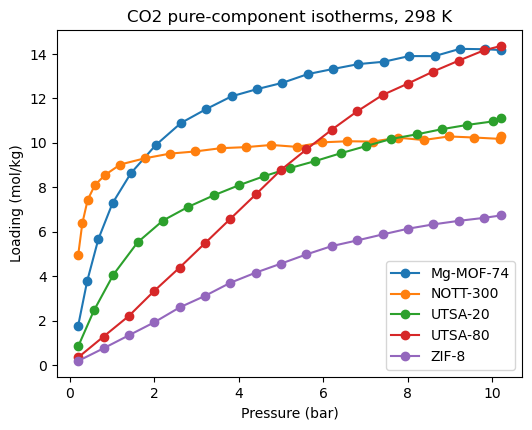

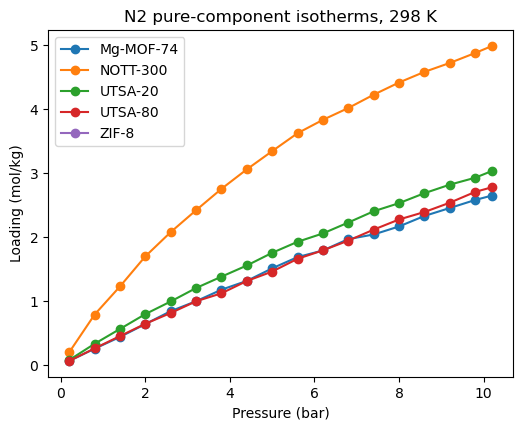

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import ast

P_TO_BAR = 1.0  

co2 = {"Mg-MOF-74": mgMOF74_co2, "NOTT-300": nott300_co2,
       "UTSA-20": utsa20_co2, "UTSA-80": utsa80_co2, "ZIF-8": zif8_co2}
n2  = {"Mg-MOF-74": mgMOF74_n2, "NOTT-300": nott300_n2,
       "UTSA-20": utsa20_n2, "UTSA-80": utsa80_n2, "ZIF-8": zif8_n2}

def isotherm(df):
    kv = dict(zip(df["Key"], df["Value"]))
    iso = kv.get("isotherm")
    if not isinstance(iso, str):  
        return np.array([]), np.array([])
    iso = ast.literal_eval(iso)

    p = np.array(iso["pressure"], float) * P_TO_BAR     # bar
    key = next(k for k in iso if "loading" in k.lower() and "dev" not in k.lower()
               and "unit" not in k.lower())
    q = np.array(iso[key], float)
    units = [str(v) for k, v in iso.items() if "unit" in k.lower()]
    if any("molec" in u.lower() for u in units):
        q = q * float(kv["conversion_factor_molec_uc_to_mol_kg"])

    order = np.argsort(p)
    return p[order], q[order]

for gas, series in (("CO2", co2), ("N2", n2)):
    fig, ax = plt.subplots(figsize=(6, 4.5))
    for name, df in series.items():
        if df is None:
            continue
        p, q = isotherm(df)
        ax.plot(p, q, "o-", label=name)
    ax.set_xlabel("Pressure (bar)")
    ax.set_ylabel("Loading (mol/kg)")
    ax.set_title(f"{gas} pure-component isotherms, 298 K")
    ax.legend()
    plt.show()

- $CO_2$ isotherms

NOTT-300 has the steepest low-pressure isotherm and saturates at about 10 mol/kg from 2 bar onwards, followed by Mg-MOF-74, which levels off near 14 mol/kg. UTSA-80 and ZIF-8 rise almost linearly, which indicates a weak affinity for $CO_2$. UTSA-80 does not saturate and reaches the highest loading at 10 bar (about 14.4 mol/kg), whereas ZIF-8 has the lowest loading over the whole range. At low pressure the isotherms are in the Henry regime ($q \approx K_H P$), so the ordering follows the affinity of the framework for $CO_2$ (NOTT-300 > Mg-MOF-74 > UTSA-20 > UTSA-80 > ZIF-8), while at high pressure it is controlled by the pore volume.

NOTT-300 has the steepest low-pressure isotherm and saturates at about 10 mol/kg from 2 bar, followed by Mg-MOF-74, which levels off near 14 mol/kg. These plateaux correspond to the saturation capacity, reached when the pores are full, and they are set by the available pore volume. UTSA-80 and ZIF-8 rise almost linearly, which indicates a weak affinity for $CO_2$. UTSA-80 does not reach a plateau and has the highest loading at 10 bar (about 14.4 mol/kg), whereas ZIF-8 has the lowest loading over the whole range. At low pressure the isotherms are in the Henry regime ($q \approx K_H P$), so the ordering follows the affinity of the framework for $CO_2$ (NOTT-300 > Mg-MOF-74 > UTSA-20 > UTSA-80 > ZIF-8), while at high pressure it is controlled by the pore volume.

- $N_2$ isotherms 

The $N_2$ loadings are much lower than the $CO_2$ ones and almost linear, because $N_2$ interacts more weakly with the framework. NOTT-300 adsorbs the most $N_2$. No $N_2$ isotherm is shown for ZIF-8: the $N_2$ probe is too large to pass the narrow windows of the rigid structure (POAV = 0), so the cages are treated as inaccessible. The pore analysis classified the structure as non-porous under these simulation conditions.

### Question 4
Calculate the $CO_2$ working capacity (WC) for the different structures.

In a PSA/VSA process, the adsorbent is loaded with $CO_2$ at high pressure (adsorption) and then regenerated by lowering the pressure (desorption). The working capacity is the amount of $CO_2$ that is actually recovered during one cycle:

$$WC = q(P_{ads}) - q(P_{des})$$

where:
- $q(P_{ads})$ is the $CO_2$ loading (mol/kg) at the adsorption pressure, the amount captured from the flue gas.
- $q(P_{des})$ is the loading that remains at the desorption pressure, the $CO_2$ that stays in the pores and is not released.

Here the working capacity is estimated from two different approaches:
1. Pure-component isotherm: the working capacity is estimated using the pure CO₂ adsorption isotherm. This serves as a simplified reference.
2. Binary mixture approach using Ideal Adsorbed Solution Theory (IAST): this method accounts for competition between $CO_2$ and $N_2$. The IAST-based working capacity is used for the final material ranking.

#### Pure component isotherms

The pure-component $CO_2$ isotherms are used to calculate the working capacity at $P_{ads}$=1.0 bar and $P_{des}$=0.2 bar, respectively. This method does not account for competition between $CO_2$ and $N_2$ and is therefore used only for comparison with the binary mixture calculation.

In [33]:
P_ADS, P_DES = 1.0, 0.2  

rows = []
for name, df in co2.items():
    if df is None:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    p, q = isotherm(df)
    if p.size == 0:
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    q_ads, q_des = np.interp([P_ADS, P_DES], p, q)
    rows.append((name, q_ads, q_des, q_ads - q_des))

wc = pd.DataFrame(rows, columns=["Structure", "q_ads (mol/kg)",
                                 "q_des (mol/kg)", "WC (mol/kg)"])
wc.sort_values("WC (mol/kg)", ascending=False).round(3)

,Structure,q_ads (mol/kg),q_des (mol/kg),WC (mol/kg)
0,Mg-MOF-74,7.221,1.768,5.453
1,NOTT-300,8.769,4.942,3.827
2,UTSA-20,3.948,0.833,3.114
3,UTSA-80,1.586,0.338,1.248
4,ZIF-8,0.944,0.178,0.765


#### IAST working capacity 

The working capacity above was calculated from the pure $CO_2$ isotherms, which assumes that the gas phase contains only $CO_2$. This is not realistic: the flue gas contains about 15 % $CO_2$ and 85 % $N_2$, so the $CO_2$ partial pressure is much lower than the total pressure, and $N_2$ competes with $CO_2$ for the adsorption sites. The pure-component working capacity therefore does not represent the real behaviour of the materials but can serve as a comparison.

To account for the mixture, the loadings are predicted with the Ideal Adsorbed Solution Theory (IAST), which uses only the pure-component isotherms. IAST assumes that the adsorbed phase behaves as an ideal solution, and it finds the composition of that phase from the condition that both components have the same spreading pressure.

In [34]:
%pip install pyast


  Preparing metadata (setup.py): started
  Preparing metadata (setup.py): finished with status 'done'
  Created wheel for pyast: filename=pyast-1.0-py3-none-any.whl size=5086 sha256=88cad8b950429b96ed4e8613e5f964d3948b4f3acca3f61916cee66f775878fa
  Stored in directory: c:\users\marie\appdata\local\pip\cache\wheels\e4\33\85\c9dfa6d847ecf0903e34d36d73d1910d27893f31c919a7d8f8
Successfully built pyast


In [35]:
from scipy.optimize import curve_fit, brentq

def langmuir(p, qm, b):
    return qm * b * p / (1 + b * p)

def fit(df):
    p, q = isotherm(df)
    return curve_fit(langmuir, p, q, p0=[max(q), 0.2],
                     bounds=(0, np.inf))[0]

def has_isotherm(df):
    return df is not None and isotherm(df)[0].size > 0

def iast(c, n, P=1.0, y=(0.15, 0.85)):
    params = [c, n]
    y = np.array(y)

    def p0(pi):
        return np.array([np.expm1(pi / qm) / b for qm, b in params])

    pi = brentq(lambda pi: P * np.sum(y / p0(pi)) - 1, 1e-10, 100)
    pressures = p0(pi)
    x = P * y / pressures
    q0 = np.array([langmuir(p, *par) for p, par in zip(pressures, params)])
    q = x / np.sum(x / q0)
    return q[0], q[1], (q[0] / q[1]) * (y[1] / y[0])

rows = []
for name in co2:
    if name == "ZIF-8":          # no N2 isotherm
        rows.append((name, np.nan, np.nan, np.nan))
        continue
    c, n = fit(co2[name]), fit(n2[name])
    q_ads = iast(c, n, P=1.0)[0]
    q_des = iast(c, n, P=0.2)[0]
    rows.append((name, q_ads, q_des, q_ads - q_des))

wc_iast = pd.DataFrame(rows, columns=["Structure", "q_ads (mol/kg)",
                                      "q_des (mol/kg)", "WC IAST (mol/kg)"])
wc_iast.round(3).fillna("-")

,Structure,q_ads (mol/kg),q_des (mol/kg),WC IAST (mol/kg)
0,Mg-MOF-74,1.662,0.369,1.293
1,NOTT-300,4.379,1.401,2.979
2,UTSA-20,0.727,0.155,0.571
3,UTSA-80,0.301,0.061,0.24
4,ZIF-8,-,-,-


Each pure isotherm was first fitted with a Langmuir model. The fit also gives a smooth extrapolation below 0.2 bar, which is needed because the $CO_2$ partial pressure at desorption (about 0.03 bar) is lower than the lowest simulated pressure. The $CO_2$ loading in the mixture was then calculated at $P_{ads} = 1$ bar and $P_{des} = 0.2$ bar (total pressures) with $y_{CO_2} = 0.15$ and $y_{N_2} = 0.85$ at 298 K. The same gas composition is used at desorption, which is a simplification. No value is given for ZIF-8, because its $N_2$ isotherm does not exist (POAV = 0 for $N_2$), so the mixture cannot be computed.

#### Comparison 

In [36]:
comp = wc[["Structure", "WC (mol/kg)"]].rename(
    columns={"WC (mol/kg)": "WC pure CO2 (mol/kg)"}
).merge(wc_iast[["Structure", "WC IAST (mol/kg)"]], on="Structure")
comp["Retention"] = comp["WC IAST (mol/kg)"] / comp["WC pure CO2 (mol/kg)"]
comp.round(3).fillna("-")

,Structure,WC pure CO2 (mol/kg),WC IAST (mol/kg),Retention
0,Mg-MOF-74,5.453,1.293,0.237
1,NOTT-300,3.827,2.979,0.778
2,UTSA-20,3.114,0.571,0.183
3,UTSA-80,1.248,0.24,0.192
4,ZIF-8,0.765,-,-


For all frameworks except ZIF-8, the working capacity is lower in the mixture than in the pure-component case. This is mainly a partial-pressure effect: in the flue gas, $CO_2$ is present at only 0.15 bar when the total pressure is 1 bar, and at about 0.03 bar when it is 0.2 bar, so the frameworks work on the low-pressure part of their isotherms. The competition with $N_2$ plays a smaller role, because the $N_2$ isotherms are almost linear and low, which means that $N_2$ is weakly adsorbed.

The ranking also changes. NOTT-300 becomes the best material in the mixture, while Mg-MOF-74, which had the highest working capacity with pure $CO_2$, loses most of its capacity. This follows from the shape of the isotherms: NOTT-300 has by far the steepest isotherm at low pressure (the highest Henry coefficient), so it still adsorbs a significant amount of $CO_2$ at a low partial pressure. Mg-MOF-74 and the UTSA frameworks need a higher $CO_2$ pressure to fill their pores, so they are less loaded under flue-gas conditions.

In conclusion, the working capacity from the pure $CO_2$ isotherms ranks the materials as Mg-MOF-74 (5.45 mol/kg) > NOTT-300 (3.83 mol/kg) > UTSA-20 (3.11 mol/kg) > UTSA-80 (1.25 mol/kg) > ZIF-8 (0.77 mol/kg), but it neglects the $CO_2$ partial pressure and the competition with $N_2$. When the flue-gas composition is taken into account with IAST, all working capacities decrease and the ranking becomes NOTT-300 (2.98 mol/kg) > Mg-MOF-74 (1.29 mol/kg) > UTSA-20 (0.57 mol/kg) > UTSA-80 (0.24 mol/kg). ZIF-8 could not be evaluated in the mixture because it has no $N_2$ isotherm, but it ranks last in the pure-component case. The IAST ranking is closer to flue-gas conditions, with NOTT-300 as the most promising material.

### Question 5
Calculate the $CO_2$/$N_2$ selectivity (S) for the different structures.

In [37]:
results = []

for name in co2:
    if not (has_isotherm(co2[name]) and has_isotherm(n2[name])):
        p, q = isotherm(co2[name])
        results.append([name, np.interp(1, p, q), np.nan, np.nan])
    else:
        results.append([name, *iast(fit(co2[name]), fit(n2[name]))])

selectivity_df = pd.DataFrame(
    results, columns=["Structure", "q_CO2", "q_N2", "Selectivity"]
)

display(selectivity_df.round(3).fillna("-"))

,Structure,q_CO2,q_N2,Selectivity
0,Mg-MOF-74,1.662,0.251,37.474
1,NOTT-300,4.379,0.45,55.093
2,UTSA-20,0.727,0.326,12.618
3,UTSA-80,0.301,0.269,6.345
4,ZIF-8,0.944,-,-


The $CO_2$/$N_2$ selectivity was calculated using Ideal Adsorbed Solution Theory (IAST) as in the previous question, based on the pure-component adsorption isotherms obtained from GCMC simulations at 298 K previously. The flue gas was assumed to contain 15% $CO_2$ and 85% $N_2$ as mentionned in the instructions, at a total adsorption pressure of 1 bar.

The selectivity is defined as:

$S_{\mathrm{CO_2/N_2}}=\frac{q_{\mathrm{CO_2}}}{q_{\mathrm{N_2}}}\times\frac{0.85}{0.15}$

A higher selectivity indicates a stronger preference for $CO_2$ adsorption over $N_2$, which is desirable for $CO_2$ capture from flue gas.

Ranking the structures in order of increasing selectivity, therefore in prefered $CO_2$ adsorption over $N_2$:

UTSA-80 < UTSA-20 < Mg-MOF-74 < NOTT-300

To conclude this question, the highest selectivity computed was for the NOTT-300 mof with a selectivity of 55.093. This is in compliance with the previous questions where either NOT-300 or Mg-MOF-74 structures proved to be more adequate for the PSA/VSA applications. 

### Question 6
Rank the structures using a WC vs. S plot.

The structures are ranked by comparing their $CO_2$ working capacity and $CO_2/N_2$ selectivity.

The IAST working capacities obtained in Question 4 are plotted against the selectivities calculated in Question 5. An ideal adsorbent should combine a high working capacity, meaning that a large amount of $CO_2$ can be recovered during each PSA/VSA cycle, with a high selectivity for $CO_2$ over $N_2$.

Therefore, materials located toward the upper-right region of the WC vs. selectivity plot are the most promising.

In [9]:
ranking = (
    wc_iast[["Structure", "WC IAST (mol/kg)"]]
    .merge(
        selectivity_df[["Structure", "Selectivity"]],
        on="Structure"
    )
    .dropna()
)

ranking

,Structure,WC IAST (mol/kg),Selectivity
0,Mg-MOF-74,1.292986,37.474434
1,NOTT-300,2.978728,55.093002
2,UTSA-20,0.571094,12.617850
3,UTSA-80,0.240002,6.345060


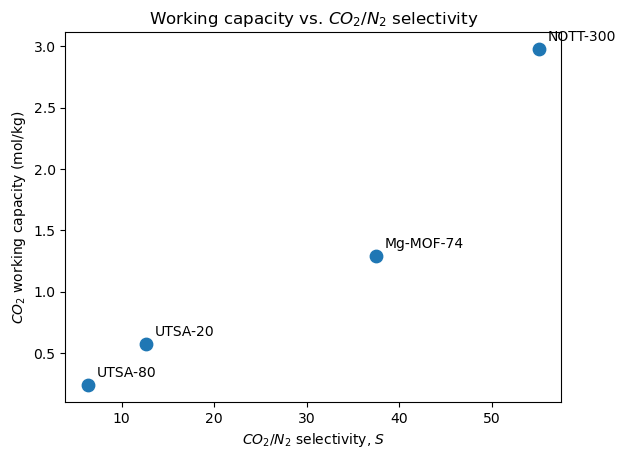

In [19]:
plt.scatter(
    ranking["Selectivity"],
    ranking["WC IAST (mol/kg)"],
    s=80
)

for _, row in ranking.iterrows():
    plt.annotate(
        row["Structure"],
        (row["Selectivity"], row["WC IAST (mol/kg)"]),
        xytext=(6, 6),
        textcoords="offset points"
    )

plt.xlabel(r"$CO_2/N_2$ selectivity, $S$")
plt.ylabel(r"$CO_2$ working capacity (mol/kg)")
plt.title(r"Working capacity vs. $CO_2/N_2$ selectivity")
plt.show()

The WC vs. selectivity plot shows a clear separation between the different materials.

NOTT-300 combines the highest working capacity ($2.979$ mol/kg) with the highest $CO_2/N_2$ selectivity ($55.093$), which makes it the best MOF according to the two criteria considered here.

Mg-MOF-74 ranks second, with a working capacity of $1.293$ mol/kg and a selectivity of $37.474$, followed by UTSA-20 and UTSA-80.

The ranking obtained from the WC vs. selectivity screening is therefore

$$
\text{NOTT-300} > \text{Mg-MOF-74} > \text{UTSA-20} > \text{UTSA-80}
$$

ZIF-8 is not included in the plot because no $N_2$ isotherm was obtained under the rigid-framework simulation conditions. Consequently, its binary IAST working capacity and $CO_2/N_2$ selectivity could not be calculated.

### Question 7
Is the screening model conclusive as to which material performs best in a PSA/VSA process for post-combustion $CO_2$ capture? Discuss the level at which the screening was performed and come up with more complex key performance indicators.

The results obtained in Question 6 suggest that NOTT-300 is the best material among the MOFs that could be evaluated, since it has both the highest working capacity and the highest $CO_2/N_2$ selectivity. However, this result is not sufficient to conclude that NOTT-300 would necessarily be the best material in a real PSA/VSA process.

In this project, the comparison is based mainly on the adsorption behaviour of the materials, not on a full simulation of the PSA/VSA process. The pore analysis was first used to characterize the structures, while the Henry coefficients and pure-component isotherms described their adsorption behaviour. IAST was then used to estimate the adsorption of the $CO_2/N_2$ mixture, and the materials were finally compared using their working capacity and selectivity.

These two criteria are important, but they do not describe the complete PSA/VSA process. For example, all the calculations assume that adsorption equilibrium is reached. In a real process, adsorption and desorption take place during a limited amount of time, so a material with a high equilibrium capacity could still perform poorly if the gases diffuse too slowly through its pores.

The energy required to regenerate the adsorbent is also not considered. A strong interaction with $CO_2$ is useful for capturing it at low partial pressure, but if $CO_2$ binds too strongly, it may also be more difficult to remove during the desorption step. Therefore, the heat of adsorption or the energy required for regeneration would also be useful when comparing the materials.

A more complete evaluation could therefore consider additional key performance indicators such as:

- **$CO_2$ recovery**, corresponding to the fraction of the incoming $CO_2$ that is actually captured;
- **$CO_2$ purity**, corresponding to the fraction of $CO_2$ in the recovered gas stream;
- **energy consumption**, especially the energy required for vacuum, regeneration and compression;
- **adsorption/desorption kinetics**, to determine whether the material can adsorb and release the gases fast enough during a real cycle.

Therefore, the present model is useful for identifying promising materials, and according to the criteria studied here NOTT-300 performs best. However, a process-level study including the cyclic operation of the PSA/VSA unit would be necessary before concluding that it is the best material for a real post-combustion $CO_2$ capture process.

### Question 8
Organization of the report.